# Лабораторная работа № 1

**Определение параметров за косым скачком уплотнения на клине с использованием численных методов решения нелинейных уравнений**

Вариант 8

## 1. Исходные данные

Для задания 1: $p_1=60000$ Па, $T_1=320$ К, $M_1=4$, $\beta=25^\circ$, метод половинного деления.

Для задания 2: $e^x+x-3=0$ на $[0,2]$, метод Ньютона.

В задании 3 уравнение угла КСУ решается методом Ньютона. Расчёты выполняются при $\kappa=1.4$, $R=287$ Дж/(кг·К) и $\varepsilon=10^{-10}$.

In [23]:
from dataclasses import dataclass
from math import asin, cos, degrees, exp, isfinite, pi, radians, sin, sqrt
from pathlib import Path
from time import perf_counter_ns
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np

ScalarFunction = Callable[[float], float]

KAPPA = 1.4
R_AIR = 287.0       # Дж/(кг·К)
P1 = 60_000.0       # Па
T1 = 320.0          # К
M1 = 4.0
BETA = radians(25)  # в формулах углы используются в радианах
EPS = 1e-10
MAX_ITERATIONS = 100

FIGURES_DIR = Path('report')
FIGURES_DIR.mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')

## 2. Уравнения и аналитические производные

Угол наклона КСУ определяется из уравнения

$$f(\theta)=\sin^2\theta-\frac{\kappa+1}{2}\frac{\sin\theta\sin\beta}{\cos(\theta-\beta)}-\frac{1}{M_1^2}=0.$$

Для метода Ньютона используются аналитические производные

$$f'(\theta)=\sin(2\theta)-A\frac{\sin\beta\cos\beta}{\cos^2(\theta-\beta)},$$

$$f''(\theta)=2\cos(2\theta)-2A\frac{\sin\beta\cos\beta\sin(\theta-\beta)}{\cos^3(\theta-\beta)},\qquad A=\frac{\kappa+1}{2}.$$

Для второго задания $g(x)=e^x+x-3$, $g'(x)=e^x+1$, $g''(x)=e^x$.

In [24]:
def shock_function(theta: float) -> float:
    A = (KAPPA + 1.0) / 2.0
    return (sin(theta) ** 2
            - A * sin(theta) * sin(BETA) / cos(theta - BETA)
            - 1.0 / M1 ** 2)

def shock_first_derivative(theta: float) -> float:
    A = (KAPPA + 1.0) / 2.0
    return (sin(2.0 * theta)
            - A * sin(BETA) * cos(BETA) / cos(theta - BETA) ** 2)

def shock_second_derivative(theta: float) -> float:
    A = (KAPPA + 1.0) / 2.0
    return (2.0 * cos(2.0 * theta)
            - 2.0 * A * sin(BETA) * cos(BETA) * sin(theta - BETA)
            / cos(theta - BETA) ** 3)

def task2_function(x: float) -> float:
    return exp(x) + x - 3.0

def task2_first_derivative(x: float) -> float:
    return exp(x) + 1.0

def task2_second_derivative(x: float) -> float:
    return exp(x)

## 3. Численные методы

Метод половинного деления сохраняет половину текущего отрезка, на концах которой функция имеет разные знаки. Критерий остановки: $(b_n-a_n)/2\leq\varepsilon$.

Метод Ньютона строит последовательность $x_{n+1}=x_n-f(x_n)/f'(x_n)$. Критерий остановки: $|x_{n+1}-x_n|\leq\varepsilon$. В реализации также контролируются нулевая производная и выход приближения за заданный отрезок.

In [25]:
@dataclass(frozen=True)
class RootResult:
    root: float
    value: float
    iterations: int
    history: tuple[float, ...]

def bisection(function: ScalarFunction, left: float, right: float,
              tolerance: float = EPS, max_iterations: int = MAX_ITERATIONS) -> RootResult:
    if not left < right:
        raise ValueError('Левая граница должна быть меньше правой')
    f_left, f_right = function(left), function(right)
    if f_left * f_right > 0:
        raise ValueError('На концах отрезка функция должна иметь разные знаки')

    history = []
    for iteration in range(1, max_iterations + 1):
        middle = (left + right) / 2.0
        f_middle = function(middle)
        history.append(middle)
        if f_middle == 0:
            return RootResult(middle, f_middle, iteration, tuple(history))
        if f_left * f_middle < 0:
            right = middle
        else:
            left, f_left = middle, f_middle
        if (right - left) / 2.0 <= tolerance:
            root = (left + right) / 2.0
            return RootResult(root, function(root), iteration, tuple(history))
    raise RuntimeError('Метод половинного деления не сошёлся')

def newton(function: ScalarFunction, derivative: ScalarFunction, initial: float,
           bracket: tuple[float, float], tolerance: float = EPS,
           max_iterations: int = MAX_ITERATIONS) -> RootResult:
    left, right = bracket
    if not left <= initial <= right:
        raise ValueError('Начальное приближение находится вне отрезка')

    current = initial
    history = [current]
    for iteration in range(1, max_iterations + 1):
        derivative_value = derivative(current)
        if abs(derivative_value) < 1e-15:
            raise ZeroDivisionError('Получена нулевая производная')
        following = current - function(current) / derivative_value
        if not isfinite(following) or not left <= following <= right:
            raise RuntimeError('Итерация вышла за отрезок локализации')
        history.append(following)
        if abs(following - current) <= tolerance:
            return RootResult(following, function(following), iteration, tuple(history))
        current = following
    raise RuntimeError('Метод Ньютона не сошёлся')

### Проверка условий на отрезке

Помимо смены знака проверяются диапазоны первой и второй производных. Для метода Ньютона вычисляется минимальный запас в условии

$$f(x)f''(x)<f'(x)^2 \quad\Longleftrightarrow\quad f'(x)^2-f(x)f''(x)>0.$$

In [26]:
def check_interval(function, derivative, second_derivative, left, right, samples=10_001):
    values = []
    for index in range(samples):
        x = left + (right - left) * index / (samples - 1)
        f, first, second = function(x), derivative(x), second_derivative(x)
        values.append((first, second, first ** 2 - f * second))
    return {
        'sign_change': function(left) * function(right) < 0,
        'derivative_range': (min(v[0] for v in values), max(v[0] for v in values)),
        'second_derivative_range': (min(v[1] for v in values), max(v[1] for v in values)),
        'newton_margin_min': min(v[2] for v in values),
    }

def find_sign_change_intervals(function, left, right, steps=10_000):
    intervals = []
    x_left, f_left = left, function(left)
    for index in range(1, steps + 1):
        x_right = left + (right - left) * index / steps
        f_right = function(x_right)
        if f_left * f_right < 0:
            intervals.append((x_left, x_right))
        x_left, f_left = x_right, f_right
    return intervals

## 4. Задание 1 — угол КСУ и параметры потока

Сначала отделим все корни в физическом диапазоне от угла Маха $\mu=\arcsin(1/M_1)$ до $90^\circ$. Уравнение имеет два корня. По условию задачи выбирается меньший корень, соответствующий устойчивому слабому скачку; больший корень относится к неустойчивому сильному скачку.

Угол Маха: 14.478°
Корни: 38.459°, 81.820°


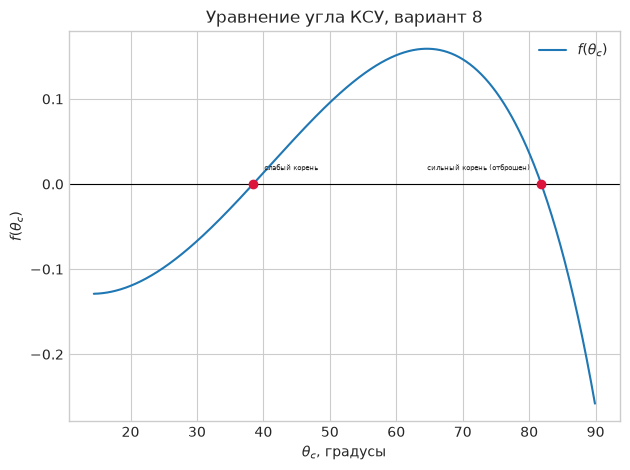

In [27]:
physical_left = asin(1.0 / M1)
root_intervals = find_sign_change_intervals(shock_function, physical_left, pi / 2 - 1e-8)
all_shock_roots = [bisection(shock_function, *interval).root for interval in root_intervals]

print(f'Угол Маха: {degrees(physical_left):.3f}°')
print('Корни:', ', '.join(f'{degrees(root):.3f}°' for root in all_shock_roots))

theta_degrees = np.linspace(degrees(physical_left), 89.9, 800)
function_values = [shock_function(radians(theta)) for theta in theta_degrees]

fig, ax = plt.subplots()
ax.plot(theta_degrees, function_values, label=r'$f(\theta_c)$')
ax.axhline(0, color='black', linewidth=0.8)
ax.scatter([degrees(root) for root in all_shock_roots], [0, 0],
           color='crimson', zorder=3)
ax.annotate('слабый корень', (degrees(all_shock_roots[0]), 0),
            xytext=(8, 10), textcoords='offset points', fontsize=5)
ax.annotate('сильный корень (отброшен)', (degrees(all_shock_roots[1]), 0),
            xytext=(-8, 10), textcoords='offset points', ha='right', fontsize=5)
ax.set(title='Уравнение угла КСУ, вариант 8',
       xlabel=r'$\theta_c$, градусы', ylabel=r'$f(\theta_c)$')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'shock_function.svg')
plt.show()

Слабый корень локализован на $[35^\circ,40^\circ]$. На этом отрезке функция меняет знак, а первая производная положительна, поэтому корень существует и единственен.

In [28]:
weak_bracket = (radians(35), radians(40))
shock_check = check_interval(
    shock_function, shock_first_derivative, shock_second_derivative, *weak_bracket
)
shock_bisection = bisection(shock_function, *weak_bracket)

print(f'f(35°) = {shock_function(weak_bracket[0]):.6f}')
print(f'f(40°) = {shock_function(weak_bracket[1]):.6f}')
print(f'theta = {degrees(shock_bisection.root):.10f}°')
print(f'Итераций: {shock_bisection.iterations}')
print(f'f(theta) = {shock_bisection.value:.2e}')

f(35°) = -0.028882
f(40°) = 0.013192
theta = 38.4588697786°
Итераций: 29
f(theta) = -9.90e-12


### Расчёт параметров за скачком

Используются соотношения

$$\rho_1=\frac{p_1}{RT_1},\quad a_1=\sqrt{\kappa RT_1},\quad v_1=M_1a_1,$$

$$u_1=1-\frac{\sin(\theta_c-\beta)\cos\theta_c}{\sin\theta_c\cos(\theta_c-\beta)},\quad \rho_2=\frac{\rho_1}{1-u_1},$$

$$p_2=p_1+\rho_1u_1v_{1n}^2,\quad T_2=\frac{p_2}{\rho_2R},\quad M_2=\frac{v_2}{\sqrt{\kappa RT_2}}.$$

In [29]:
def flow_parameters(theta: float):
    rho1 = P1 / (R_AIR * T1)
    a1 = sqrt(KAPPA * R_AIR * T1)
    v1 = M1 * a1
    v1_normal = v1 * sin(theta)
    u1 = 1.0 - (sin(theta - BETA) * cos(theta)
                / (sin(theta) * cos(theta - BETA)))
    rho2 = rho1 / (1.0 - u1)
    p2 = P1 + rho1 * u1 * v1_normal ** 2
    temperature2 = p2 / (rho2 * R_AIR)
    v2 = v1 * cos(theta) / cos(theta - BETA)
    a2 = sqrt(KAPPA * R_AIR * temperature2)
    return {'rho1': rho1, 'a1': a1, 'v1': v1, 'u1': u1,
            'rho2': rho2, 'p2': p2, 'T2': temperature2,
            'v2': v2, 'a2': a2, 'M2': v2 / a2}

flow = flow_parameters(shock_bisection.root)

print(f"p2 = {flow['p2']:.3g} Па")
print(f"T2 = {flow['T2']:.3g} К")
print(f"rho2 = {flow['rho2']:.3g} кг/м³")
print(f"M2 = {flow['M2']:.3g}")

p2 = 4.23e+05 Па
T2 = 680 К
rho2 = 2.17 кг/м³
M2 = 2.21


## 5. Задание 2 — уравнение $e^x+x-3=0$

На $[0,2]$ имеем $g(0)=-2$ и $g(2)=6.39$, поэтому корень существует. Производные $g'(x)=e^x+1>0$ и $g''(x)=e^x>0$ непрерывны и сохраняют знак, следовательно, корень единственен.

Условие Ньютона выполняется на всём отрезке, поскольку

$$g'(x)^2-g(x)g''(x)=(5-x)e^x+1\geq6>0.$$

Начальное приближение: $x_0=2$.

In [30]:
task2_bracket = (0.0, 2.0)
task2_check = check_interval(
    task2_function, task2_first_derivative, task2_second_derivative, *task2_bracket
)
task2_result = newton(
    task2_function, task2_first_derivative, initial=2.0, bracket=task2_bracket
)

print(f'x = {task2_result.root:.10f}')
print(f'g(x) = {task2_result.value:.2e}')
print(f'Итераций: {task2_result.iterations}')

x = 0.7920599684
g(x) = 0.00e+00
Итераций: 6


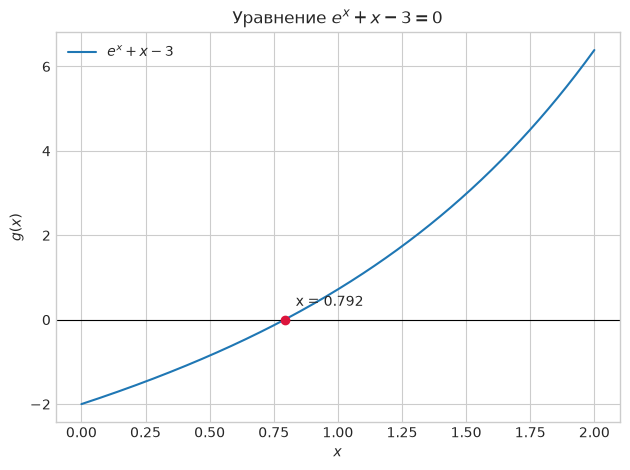

In [31]:
x_values = np.linspace(*task2_bracket, 500)
function_values = [task2_function(x) for x in x_values]

fig, ax = plt.subplots()
ax.plot(x_values, function_values, label=r'$e^x+x-3$')
ax.axhline(0, color='black', linewidth=0.8)
ax.scatter([task2_result.root], [0], color='crimson', zorder=3)
ax.annotate(f'x = {task2_result.root:.3f}', (task2_result.root, 0),
            xytext=(8, 10), textcoords='offset points')
ax.set(title=r'Уравнение $e^x+x-3=0$', xlabel='$x$', ylabel='$g(x)$')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'task2_function.svg')
plt.show()

## 6. Задание 3 — уравнение КСУ методом Ньютона

Используется тот же отрезок $[35^\circ,40^\circ]$ и начальное приближение $\theta_0=37.5^\circ$. Проверка из задания 1 подтверждает постоянство знаков производных. Минимум $f'(\theta)^2-f(\theta)f''(\theta)$ на отрезке положителен, поэтому условие сходимости метода Ньютона выполнено.

In [32]:
shock_newton = newton(
    shock_function, shock_first_derivative, initial=radians(37.5), bracket=weak_bracket
)

print(f'theta = {degrees(shock_newton.root):.10f}°')
print(f'f(theta) = {shock_newton.value:.2e}')
print(f'Итераций: {shock_newton.iterations}')

theta = 38.4588697797°
f(theta) = 0.00e+00
Итераций: 4


## 7. Сравнение методов

Для сравнения используется реальное время `perf_counter_ns`. Выводится среднее время одного решения по 10000 повторениям.

In [33]:
def average_runtime_ns(action, repetitions=10_000):
    started = perf_counter_ns()
    for _ in range(repetitions):
        action()
    return (perf_counter_ns() - started) / repetitions

bisection_time = average_runtime_ns(
    lambda: bisection(shock_function, *weak_bracket)
)
newton_time = average_runtime_ns(
    lambda: newton(shock_function, shock_first_derivative,
                   initial=radians(37.5), bracket=weak_bracket)
)
difference = abs(degrees(shock_bisection.root - shock_newton.root))

print(f'Половинное деление: {shock_bisection.iterations} итераций, {bisection_time / 1000:.2f} мкс')
print(f'Метод Ньютона: {shock_newton.iterations} итерации, {newton_time / 1000:.2f} мкс')
print(f'Разница: {difference:.2e}°')

Половинное деление: 29 итераций, 12.17 мкс
Метод Ньютона: 4 итерации, 3.06 мкс
Разница: 1.16e-09°


## 8. Выводы

1. Уравнение угла КСУ имеет два корня. Выбран физически устойчивый слабый скачок с углом $\theta_c=38.5^\circ$; сильный корень $81.8^\circ$ отброшен.
2. За скачком получены $p_2=4.23\cdot10^5$ Па, $T_2=680$ К, $\rho_2=2.17$ кг/м³ и $M_2=2.21$. Поток остаётся сверхзвуковым.
3. Корень уравнения $e^x+x-3=0$ равен $x=0.792$.
4. Для уравнения КСУ методы дали практически одинаковый результат. Метод Ньютона потребовал 4 итерации, метод половинного деления — 29, что демонстрирует более высокую скорость сходимости Ньютона при выполнении условий его применимости.